<a href="https://colab.research.google.com/github/rodrigoviannasn/MAT-422/blob/main/MAT422_HW_3_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MAT 422 — Homework 3.4: Logistic Regression

Rodrigo Vianna | 10/25/2026

In [14]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

## 3.4.1 The Sigmoid Function

Logistic regression uses the sigmoid function to convert any real number into a probability between $0$ and $1$:

$$
\sigma(z)=\frac{1}{1+e^{-z}}.
$$

When $z=0$, the sigmoid value is $0.5$. Large positive values of $z$ produce probabilities close to $1$, while large negative values produce probabilities close to $0$.

In [15]:
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))

z_values = np.array([-4, -2, 0, 2, 4])
probabilities = sigmoid(z_values)

print("Sigmoid values:")
for z, probability in zip(z_values, probabilities):
    print(f"z = {z:>2}, sigmoid(z) = {probability:.4f}")

Sigmoid values:
z = -4, sigmoid(z) = 0.0180
z = -2, sigmoid(z) = 0.1192
z =  0, sigmoid(z) = 0.5000
z =  2, sigmoid(z) = 0.8808
z =  4, sigmoid(z) = 0.9820


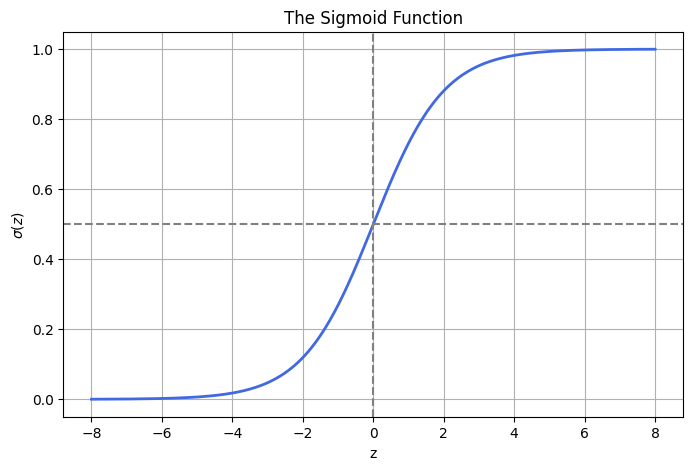

In [16]:
z_plot = np.linspace(-8, 8, 500)

plt.figure(figsize=(8, 5))
plt.plot(z_plot, sigmoid(z_plot), color="royalblue", linewidth=2)
plt.axhline(0.5, color="gray", linestyle="--")
plt.axvline(0, color="gray", linestyle="--")

plt.xlabel("z")
plt.ylabel(r"$\sigma(z)$")
plt.title("The Sigmoid Function")
plt.grid()
plt.show()

### Section Conclusion

The sigmoid graph has an S-shape and always stays between $0$ and $1$, which makes it useful for probability predictions. The printed values show that negative inputs produce low probabilities, positive inputs produce high probabilities, and $z=0$ gives a probability of $0.5$.

## 3.4.2 Binary Classification Probabilities

In binary classification, the model estimates the probability of class $1$. For this example, class $1$ represents passing an assessment and class $0$ represents not passing.

A predicted probability can be converted into a class label using a threshold of $0.5$:

$$
\hat{y}=
\begin{cases}
1, & \text{if } P(Y=1 \mid x) \geq 0.5 \\
0, & \text{if } P(Y=1 \mid x) < 0.5
\end{cases}
$$

This example uses a practice logistic model to estimate the probability of passing based on study hours.

Practice hours, predicted probability, and predicted class:

1 hours: probability of passing = 0.0293, predicted class = 0
2 hours: probability of passing = 0.1192, predicted class = 0
3 hours: probability of passing = 0.3775, predicted class = 0
4 hours: probability of passing = 0.7311, predicted class = 1
5 hours: probability of passing = 0.9241, predicted class = 1


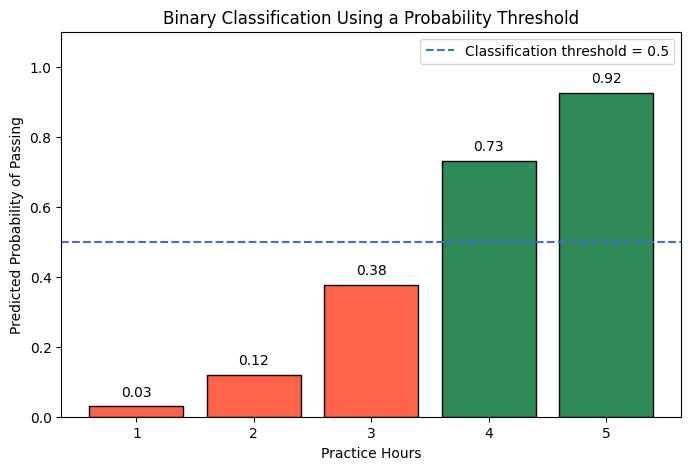

In [17]:
practice_hours = np.array([1, 2, 3, 4, 5], dtype=float)

# A practice logistic model
logit_scores = -5 + 1.5 * practice_hours
pass_probabilities = sigmoid(logit_scores)
predicted_classes = (pass_probabilities >= 0.5).astype(int)

print("Practice hours, predicted probability, and predicted class:\n")

for hours, probability, predicted_class in zip(
    practice_hours,
    pass_probabilities,
    predicted_classes
):
    print(
        f"{hours:.0f} hours: "
        f"probability of passing = {probability:.4f}, "
        f"predicted class = {predicted_class}"
    )

bar_colors = np.where(predicted_classes == 1, "seagreen", "tomato")

plt.figure(figsize=(8, 5))
bars = plt.bar(
    practice_hours,
    pass_probabilities,
    color=bar_colors,
    edgecolor="black"
)

for bar, probability in zip(bars, pass_probabilities):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        probability + 0.03,
        f"{probability:.2f}",
        ha="center"
    )

plt.axhline(
    0.5,
    color="royalblue",
    linestyle="--",
    label="Classification threshold = 0.5"
)

plt.ylim(0, 1.1)
plt.xlabel("Practice Hours")
plt.ylabel("Predicted Probability of Passing")
plt.title("Binary Classification Using a Probability Threshold")
plt.legend()
plt.show()

### Section Conclusion

The predicted probability increased as the number of practice hours increased. The classification changed from $0$ to $1$ once the predicted probability passed the threshold of $0.5$. This demonstrates how logistic regression probabilities can be used to make a binary decision.

## 3.4.3 Logistic Regression Fitting and Interpretation

A logistic-regression model estimates the probability of a binary outcome using

$$
P(Y=1 \mid x)=\sigma(\beta_0+\beta_1x).
$$

The coefficient $\beta_0$ is the intercept, while $\beta_1$ describes how the input variable changes the log-odds of the outcome. A positive slope means that larger values of $x$ increase the predicted probability of class $1$.

The code below fits a logistic-regression model with gradient descent using practice hours and pass/fail outcomes.

In [18]:
training_hours = np.array([
    0.5, 1.0, 1.5, 2.0, 2.5, 3.0,
    3.5, 4.0, 4.5, 5.0, 5.5, 6.0
])

passed = np.array([
    0, 0, 0, 0, 0, 0,
    1, 0, 1, 1, 1, 1
])

design_matrix = np.column_stack((
    np.ones_like(training_hours),
    training_hours
))

beta = np.zeros(2)
learning_rate = 0.1
iterations = 4000
loss_history = []

for _ in range(iterations):
    predicted_probabilities = sigmoid(design_matrix @ beta)

    # Binary cross-entropy loss
    loss = -np.mean(
        passed * np.log(predicted_probabilities + 1e-12)
        + (1 - passed) * np.log(1 - predicted_probabilities + 1e-12)
    )
    loss_history.append(loss)

    gradient = (
        design_matrix.T @ (predicted_probabilities - passed)
    ) / len(passed)

    beta = beta - learning_rate * gradient

final_probabilities = sigmoid(design_matrix @ beta)
final_predictions = (final_probabilities >= 0.5).astype(int)
accuracy = np.mean(final_predictions == passed)

intercept, slope = beta
decision_boundary = -intercept / slope

print("Intercept estimate:", intercept)
print("Slope estimate:", slope)
print(
    "\nLogistic regression model:"
    f"\nP(pass | hours) = sigmoid({intercept:.3f} + {slope:.3f} × hours)"
)

print("\nDecision boundary in practice hours:", decision_boundary)
print("Training accuracy:", accuracy)

print("\nHours | Actual outcome | Predicted probability | Predicted class")
for hours, actual, probability, prediction in zip(
    training_hours,
    passed,
    final_probabilities,
    final_predictions
):
    print(
        f"{hours:>4.1f}  |"
        f"       {actual}        |"
        f"        {probability:.4f}       |"
        f"        {prediction}"
    )

Intercept estimate: -8.013296029444847
Slope estimate: 2.1515581537217856

Logistic regression model:
P(pass | hours) = sigmoid(-8.013 + 2.152 × hours)

Decision boundary in practice hours: 3.7244152641579182
Training accuracy: 0.8333333333333334

Hours | Actual outcome | Predicted probability | Predicted class
 0.5  |       0        |        0.0010       |        0
 1.0  |       0        |        0.0028       |        0
 1.5  |       0        |        0.0083       |        0
 2.0  |       0        |        0.0239       |        0
 2.5  |       0        |        0.0670       |        0
 3.0  |       0        |        0.1738       |        0
 3.5  |       1        |        0.3816       |        0
 4.0  |       0        |        0.6440       |        1
 4.5  |       1        |        0.8414       |        1
 5.0  |       1        |        0.9396       |        1
 5.5  |       1        |        0.9785       |        1
 6.0  |       1        |        0.9926       |        1


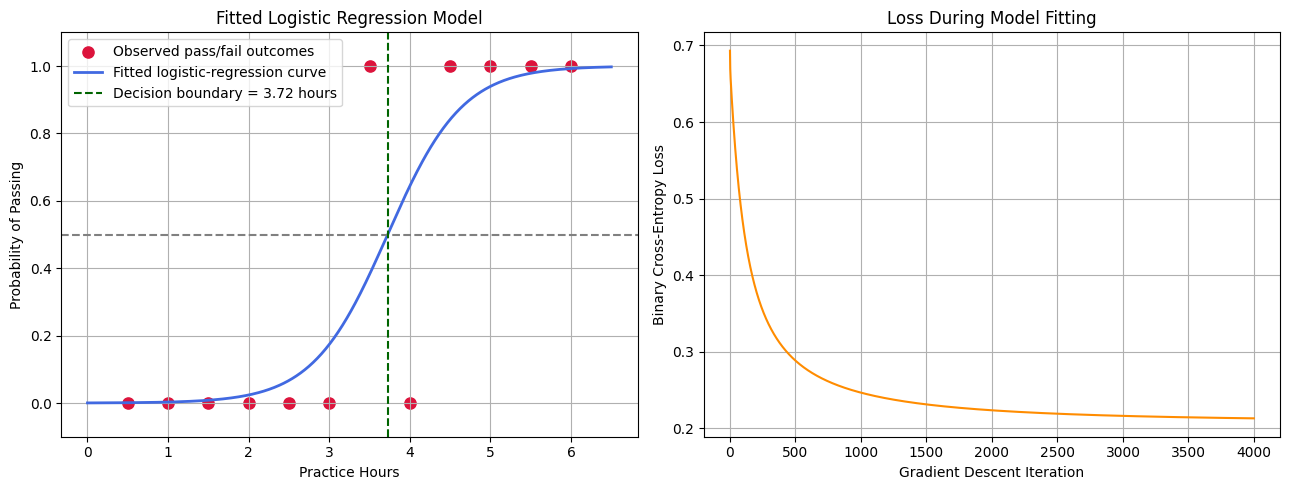

In [19]:
hours_plot = np.linspace(0, 6.5, 500)
fitted_probabilities = sigmoid(intercept + slope * hours_plot)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(
    training_hours,
    passed,
    color="crimson",
    s=65,
    label="Observed pass/fail outcomes"
)

axes[0].plot(
    hours_plot,
    fitted_probabilities,
    color="royalblue",
    linewidth=2,
    label="Fitted logistic-regression curve"
)

axes[0].axhline(0.5, color="gray", linestyle="--")
axes[0].axvline(
    decision_boundary,
    color="darkgreen",
    linestyle="--",
    label=f"Decision boundary = {decision_boundary:.2f} hours"
)

axes[0].set_xlabel("Practice Hours")
axes[0].set_ylabel("Probability of Passing")
axes[0].set_title("Fitted Logistic Regression Model")
axes[0].set_ylim(-0.1, 1.1)
axes[0].grid()
axes[0].legend()

axes[1].plot(
    np.arange(iterations),
    loss_history,
    color="darkorange"
)

axes[1].set_xlabel("Gradient Descent Iteration")
axes[1].set_ylabel("Binary Cross-Entropy Loss")
axes[1].set_title("Loss During Model Fitting")
axes[1].grid()

plt.tight_layout()
plt.show()

### Section Conclusion

The fitted model had a positive slope, so more practice hours increased the predicted probability of passing. The decision boundary identifies the number of hours where the model changes from predicting class $0$ to class $1$. The loss graph decreased during gradient descent, which shows that the model improved as it was fitted to the data.

## Conclusion / Reflection

Logistic regression gave me a different way to think about prediction. Instead of directly predicting a score or another continuous value, it predicts the chance that an outcome belongs to one of two categories. The sigmoid function is important because it converts the model output into a probability that is easy to interpret.

The practice-hours examples made the probability threshold more concrete. A model can show that the probability of passing is increasing without claiming that every student who studies a certain number of hours will definitely pass. The final fitted curve also showed how the model uses data to find a useful dividing point between the two classes.

I found the loss graph helpful because it showed that fitting a model is a process. Each gradient-descent step adjusts the coefficients so the predictions become more consistent with the observed outcomes.